# Black-Scholes-Merton Pricing and Greeks Sensitivity Analysis

**Author:** Steven Ghabyous | Master of Financial Mathematics, NC State University

This notebook implements the Black-Scholes-Merton (BSM) model for European options on a dividend-paying stock, derives the five main Greeks analytically, checks them numerically, and shows how each Greek changes with the stock price, time to expiry, and volatility.

## Contents
1. BSM pricing formulas
2. Analytical Greeks
3. Verification: put-call parity and finite-difference checks
4. Worked example: a 30-day at-the-money SPY option
5. Sensitivity analysis
6. Optional: pulling live market inputs

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

---
# 1. Black-Scholes-Merton pricing

For spot price $S$, strike $K$, time to expiry $T$ (years), risk-free rate $r$, continuous dividend yield $q$, and volatility $\sigma$:

$$d_1 = \frac{\ln(S/K) + (r - q + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

$$C = S e^{-qT} N(d_1) - K e^{-rT} N(d_2)$$

The put price comes from put-call parity: $P = C + K e^{-rT} - S e^{-qT}$.

In [2]:
def calculate_d1_d2(S, K, T, r, q, sigma):
    d1 = (math.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    return d1, d2

def bsm_call(S, K, T, r, q, sigma):
    d1, d2 = calculate_d1_d2(S, K, T, r, q, sigma)
    return S * math.exp(-q * T) * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2)

def bsm_put(S, K, T, r, q, sigma):
    return bsm_call(S, K, T, r, q, sigma) + K * math.exp(-r * T) - S * math.exp(-q * T)

def bsm_price(S, K, T, r, q, sigma, option_type='call'):
    return bsm_call(S, K, T, r, q, sigma) if option_type == 'call' else bsm_put(S, K, T, r, q, sigma)

---
# 2. Analytical Greeks

| Greek | Measures | Formula (call) |
|---|---|---|
| Delta | Change in price per $1 move in $S$ | $e^{-qT} N(d_1)$ |
| Gamma | Change in delta per $1 move in $S$ | $\dfrac{e^{-qT} N'(d_1)}{S \sigma \sqrt{T}}$ |
| Vega | Change in price per 1.00 change in $\sigma$ | $S e^{-qT} N'(d_1) \sqrt{T}$ |
| Theta | Change in price per year of time passing | see code |
| Rho | Change in price per 1.00 change in $r$ | $K T e^{-rT} N(d_2)$ |

Gamma and vega are the same for calls and puts. For readability, results are also reported in trader units: **theta per calendar day** (divide by 365), and **vega and rho per 1 percentage point** (divide by 100).

In [3]:
def delta(S, K, T, r, q, sigma, option_type='call'):
    d1, _ = calculate_d1_d2(S, K, T, r, q, sigma)
    if option_type == 'call':
        return math.exp(-q * T) * norm.cdf(d1)
    return -math.exp(-q * T) * norm.cdf(-d1)

def gamma(S, K, T, r, q, sigma):
    d1, _ = calculate_d1_d2(S, K, T, r, q, sigma)
    return norm.pdf(d1) * math.exp(-q * T) / (S * sigma * math.sqrt(T))

def vega(S, K, T, r, q, sigma):
    d1, _ = calculate_d1_d2(S, K, T, r, q, sigma)
    return S * math.exp(-q * T) * norm.pdf(d1) * math.sqrt(T)

def theta(S, K, T, r, q, sigma, option_type='call'):
    d1, d2 = calculate_d1_d2(S, K, T, r, q, sigma)
    first_term = -S * norm.pdf(d1) * sigma * math.exp(-q * T) / (2 * math.sqrt(T))
    if option_type == 'call':
        return first_term + q * S * math.exp(-q * T) * norm.cdf(d1) - r * K * math.exp(-r * T) * norm.cdf(d2)
    return first_term - q * S * math.exp(-q * T) * norm.cdf(-d1) + r * K * math.exp(-r * T) * norm.cdf(-d2)

def rho(S, K, T, r, q, sigma, option_type='call'):
    _, d2 = calculate_d1_d2(S, K, T, r, q, sigma)
    if option_type == 'call':
        return K * T * math.exp(-r * T) * norm.cdf(d2)
    return -K * T * math.exp(-r * T) * norm.cdf(-d2)

---
# 3. Verification

Two checks confirm the formulas are implemented correctly:

1. **Put-call parity** must hold exactly: $C - P = S e^{-qT} - K e^{-rT}$.
2. **Finite differences:** each analytical Greek should match a numerical derivative of the price, computed by bumping one input up and down slightly. For theta, the bump is to $T$, and theta is the negative of the derivative with respect to $T$.

In [4]:
def fd_greeks(S, K, T, r, q, sigma, option_type='call', h=1e-4):
    p = lambda S_=S, T_=T, r_=r, s_=sigma: bsm_price(S_, K, T_, r_, q, s_, option_type)
    dS = S * h
    return {
        'delta': (p(S_=S + dS) - p(S_=S - dS)) / (2 * dS),
        'gamma': (p(S_=S + dS) - 2 * p() + p(S_=S - dS)) / dS ** 2,
        'vega':  (p(s_=sigma + h) - p(s_=sigma - h)) / (2 * h),
        'theta': -(p(T_=T + h) - p(T_=T - h)) / (2 * h),
        'rho':   (p(r_=r + h) - p(r_=r - h)) / (2 * h),
    }

def analytic_greeks(S, K, T, r, q, sigma, option_type='call'):
    return {
        'delta': delta(S, K, T, r, q, sigma, option_type),
        'gamma': gamma(S, K, T, r, q, sigma),
        'vega':  vega(S, K, T, r, q, sigma),
        'theta': theta(S, K, T, r, q, sigma, option_type),
        'rho':   rho(S, K, T, r, q, sigma, option_type),
    }

test = dict(S=100, K=105, T=0.5, r=0.04, q=0.015, sigma=0.25)
C, P = bsm_call(**test), bsm_put(**test)
parity_gap = (C - P) - (test['S'] * math.exp(-test['q'] * test['T']) - test['K'] * math.exp(-test['r'] * test['T']))
print(f"Put-call parity gap: {parity_gap:.2e}\n")

print(f"{'Greek':<7}{'Type':<6}{'Analytical':>14}{'Finite diff.':>14}{'Abs. error':>12}")
for opt in ['call', 'put']:
    a, f = analytic_greeks(**test, option_type=opt), fd_greeks(**test, option_type=opt)
    for g in a:
        print(f"{g:<7}{opt:<6}{a[g]:>14.6f}{f[g]:>14.6f}{abs(a[g] - f[g]):>12.1e}")

Put-call parity gap: -7.11e-15

Greek  Type      Analytical  Finite diff.  Abs. error
delta  call        0.450081      0.450081     1.3e-09
gamma  call        0.022246      0.022246     5.6e-10
vega   call       27.808043     27.808042     9.9e-08
theta  call       -7.859822     -7.859822     2.9e-08
rho    call       19.786667     19.786667     7.4e-09
delta  put        -0.542447     -0.542447     1.3e-09
gamma  put         0.022246      0.022246     9.2e-10
vega   put        27.808043     27.808042     9.9e-08
theta  put        -5.231779     -5.231780     2.9e-08
rho    put       -31.673764    -31.673764     2.9e-08


---
# 4. Worked example: 30-day at-the-money SPY option

Inputs are fixed so the notebook gives the same results every time it runs. They are representative of SPY in early 2025: spot near \$560, an at-the-money strike, 30 days to expiry, a 4.5% risk-free rate, a 1.2% dividend yield, and 18% implied volatility.

Note that the dividend yield is entered as a decimal (0.012), not as a percentage (1.2). Mixing these up would treat it as a 120% yield and distort every Greek, including flipping the sign of theta.

In [5]:
S, K, T, r, q, sigma = 560.0, 560.0, 30 / 365, 0.045, 0.012, 0.18

print(f"Call price: ${bsm_call(S, K, T, r, q, sigma):.2f}")
print(f"Put price:  ${bsm_put(S, K, T, r, q, sigma):.2f}\n")
print(f"{'Greek':<26}{'Call':>10}{'Put':>10}")
rows = [
    ('Delta', delta(S, K, T, r, q, sigma, 'call'), delta(S, K, T, r, q, sigma, 'put')),
    ('Gamma', gamma(S, K, T, r, q, sigma), gamma(S, K, T, r, q, sigma)),
    ('Vega (per 1 vol point)', vega(S, K, T, r, q, sigma) / 100, vega(S, K, T, r, q, sigma) / 100),
    ('Theta (per day)', theta(S, K, T, r, q, sigma, 'call') / 365, theta(S, K, T, r, q, sigma, 'put') / 365),
    ('Rho (per 1% rate)', rho(S, K, T, r, q, sigma, 'call') / 100, rho(S, K, T, r, q, sigma, 'put') / 100),
]
for name, c, p in rows:
    print(f"{name:<26}{c:>10.4f}{p:>10.4f}")

Call price: $12.27
Put price:  $10.76

Greek                           Call       Put
Delta                         0.5307   -0.4683
Gamma                         0.0137    0.0137
Vega (per 1 vol point)        0.6379    0.6379
Theta (per day)              -0.2167   -0.1663
Rho (per 1% rate)             0.2342   -0.2244


**Reading the results:** the at-the-money call has a delta near 0.5, so it moves about \$0.50 for each \$1 move in SPY. Both options lose value as time passes (negative theta), and both gain about the same amount from a 1-point rise in implied volatility, since vega is identical for calls and puts.

---
# 5. Sensitivity analysis

## 5.1 Greeks across stock prices

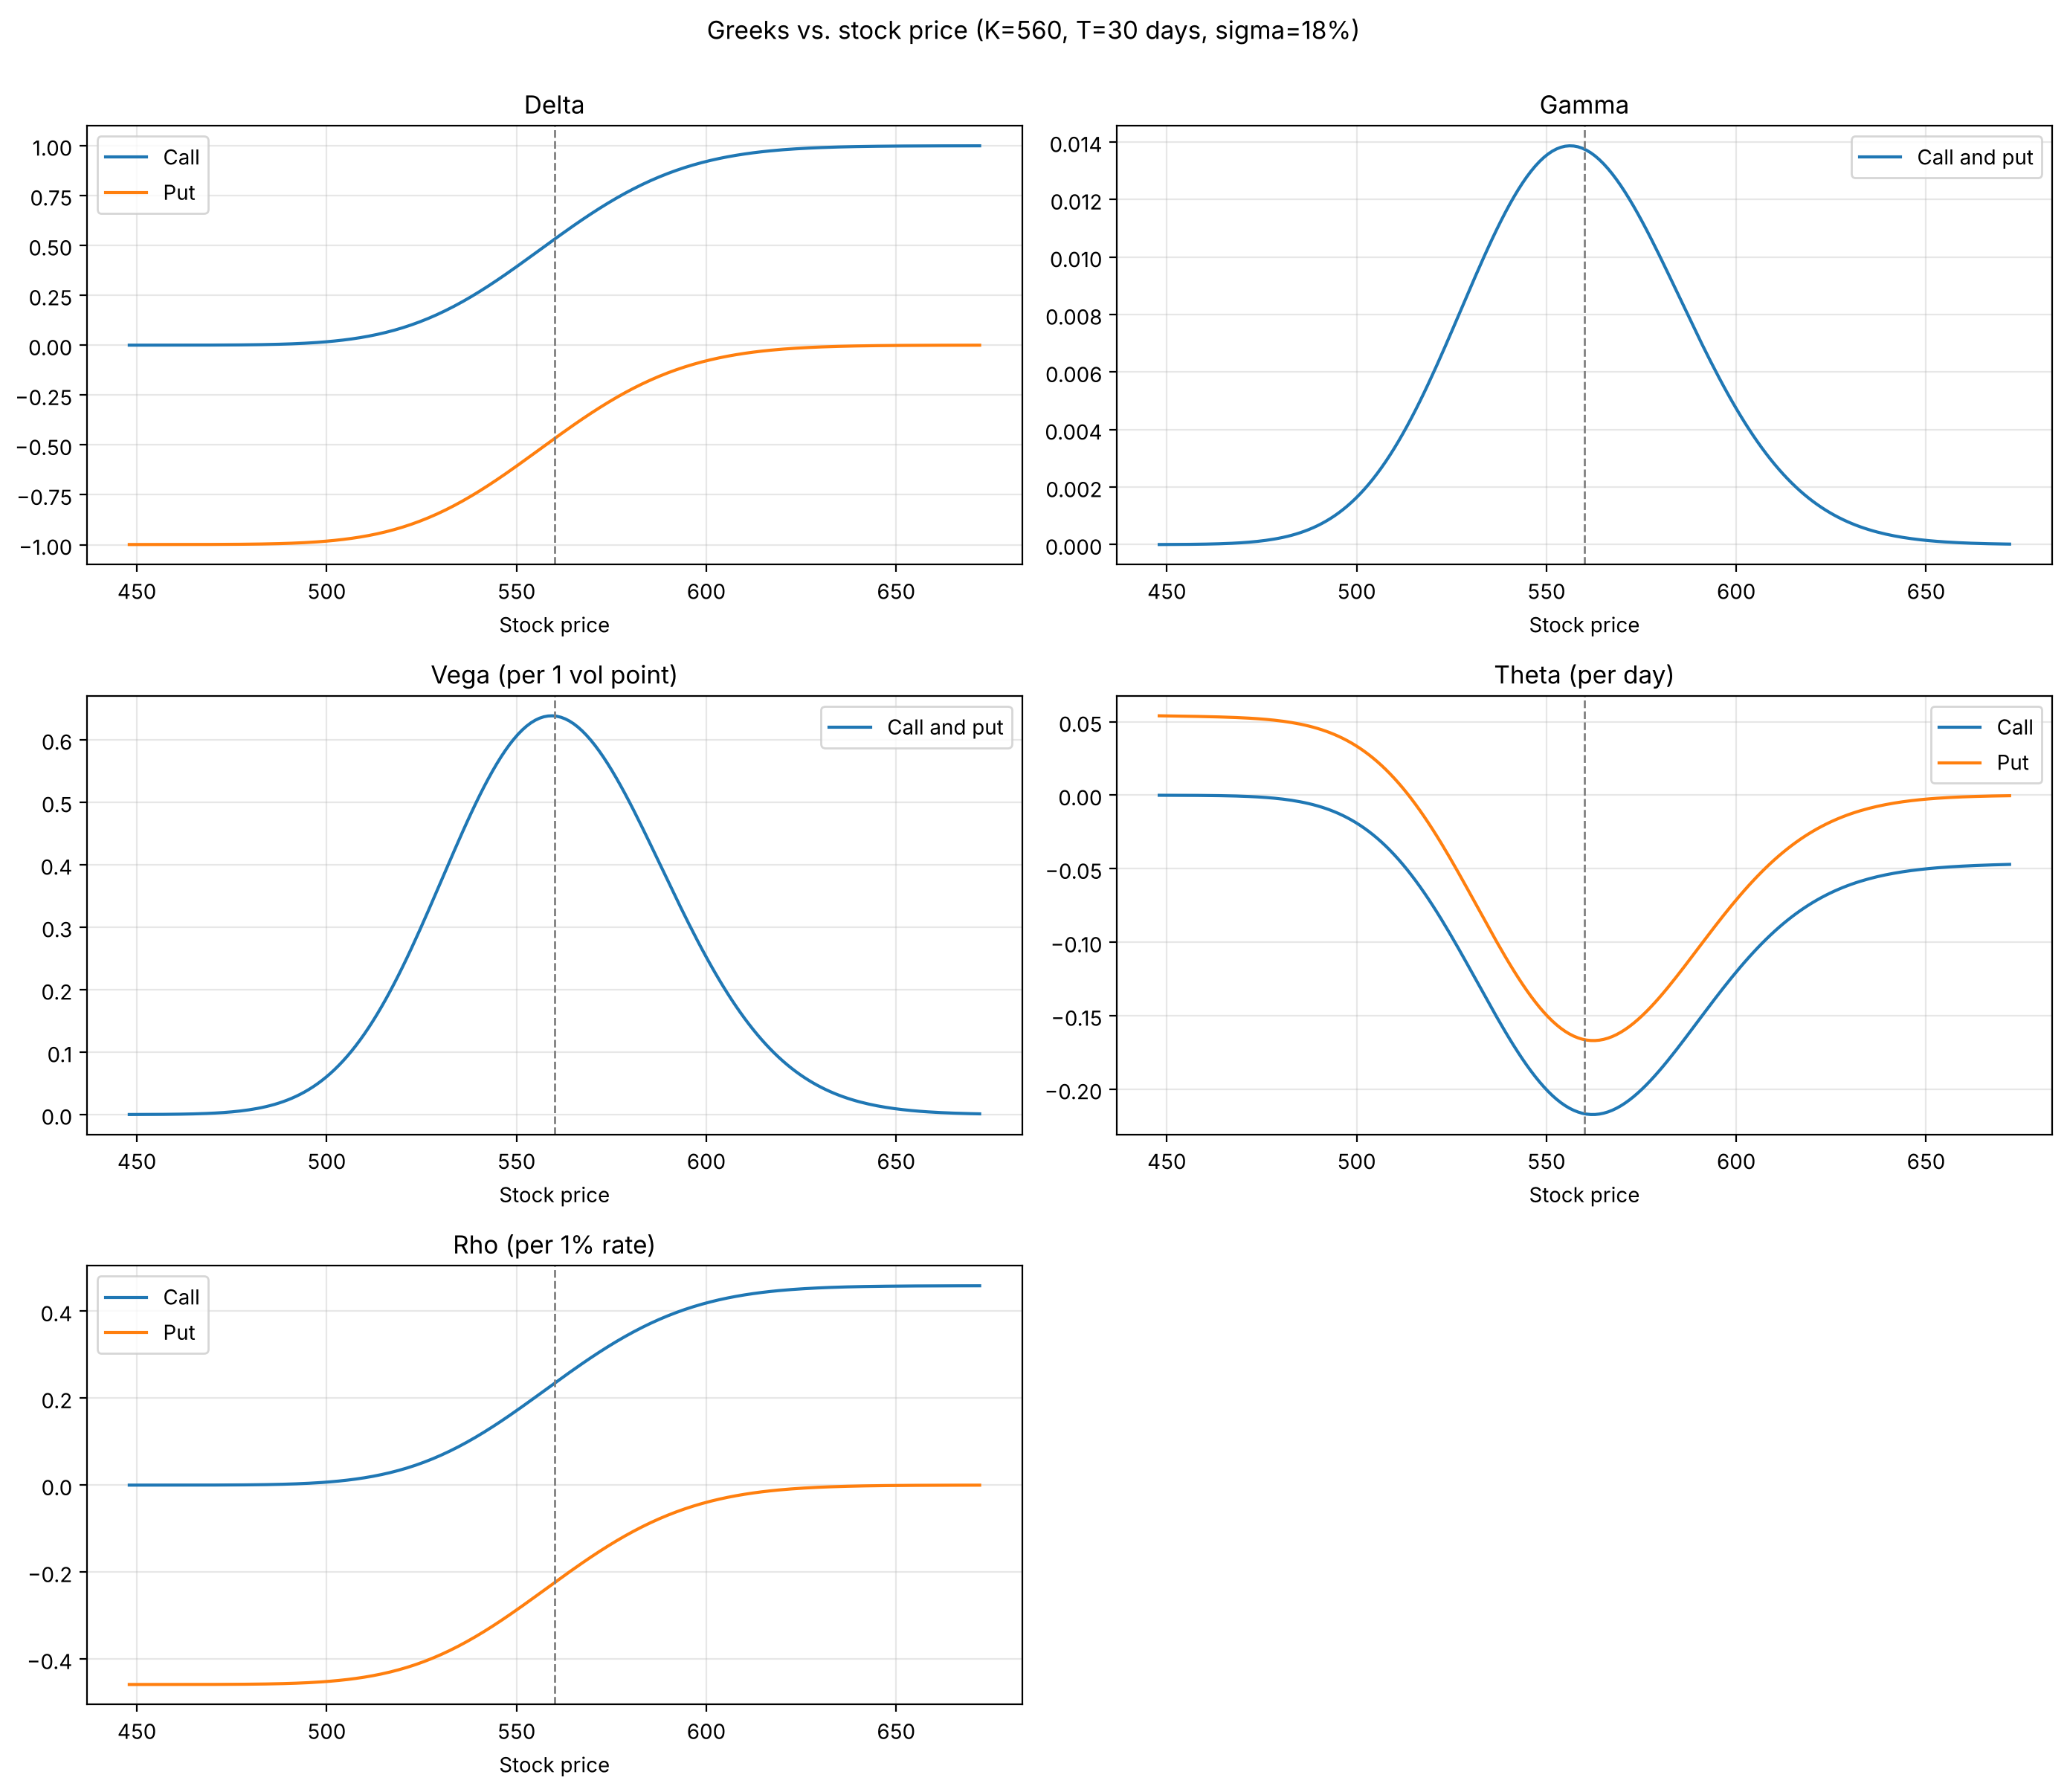

In [6]:
stock_prices = np.linspace(0.8 * K, 1.2 * K, 200)

curves = {
    'Delta': ([delta(s, K, T, r, q, sigma, 'call') for s in stock_prices], [delta(s, K, T, r, q, sigma, 'put') for s in stock_prices]),
    'Gamma': ([gamma(s, K, T, r, q, sigma) for s in stock_prices], None),
    'Vega (per 1 vol point)': ([vega(s, K, T, r, q, sigma) / 100 for s in stock_prices], None),
    'Theta (per day)': ([theta(s, K, T, r, q, sigma, 'call') / 365 for s in stock_prices], [theta(s, K, T, r, q, sigma, 'put') / 365 for s in stock_prices]),
    'Rho (per 1% rate)': ([rho(s, K, T, r, q, sigma, 'call') / 100 for s in stock_prices], [rho(s, K, T, r, q, sigma, 'put') / 100 for s in stock_prices]),
}

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, (name, (call_vals, put_vals)) in zip(axes.flat, curves.items()):
    ax.plot(stock_prices, call_vals, label='Call' if put_vals else 'Call and put')
    if put_vals:
        ax.plot(stock_prices, put_vals, label='Put')
    ax.axvline(K, color='gray', linestyle='--', linewidth=1)
    ax.set_title(name); ax.set_xlabel('Stock price'); ax.grid(True, alpha=0.3); ax.legend()
axes.flat[-1].axis('off')
plt.suptitle(f'Greeks vs. stock price (K={K:.0f}, T=30 days, sigma={sigma:.0%})', y=1.0)
plt.tight_layout()
plt.show()

**Observations:**
- **Delta** moves from 0 to 1 for the call (and -1 to 0 for the put), changing fastest near the strike.
- **Gamma** and **vega** peak at the money, where the option's outcome is most uncertain.
- **Theta** is most negative at the money: that is where the option holds the most time value to lose.

## 5.2 Gamma and theta as expiry approaches

For an at-the-money option, gamma and time decay both accelerate sharply in the final days. This is why short-dated options are so sensitive to small moves in the stock.

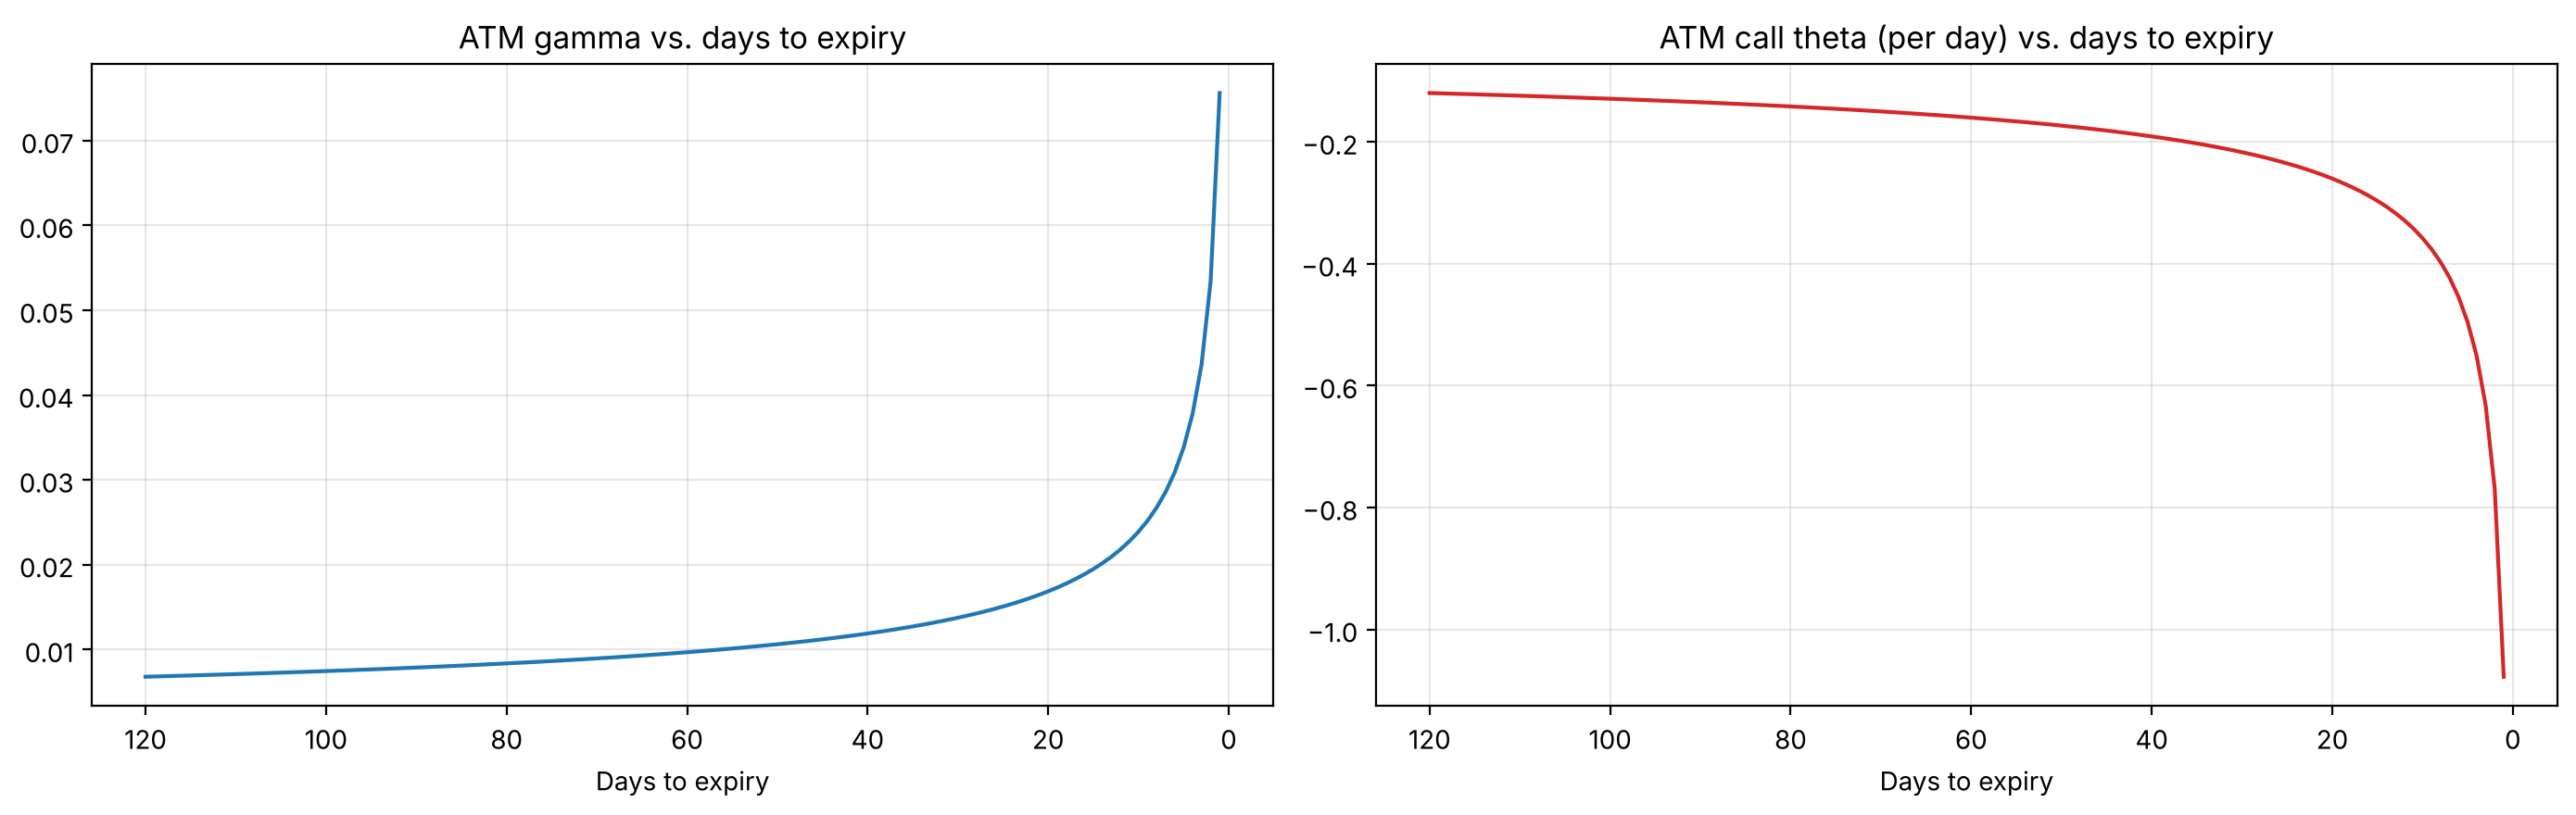

ATM gamma: 0.0097 at 60 days vs. 0.0338 at 5 days
ATM call theta per day: -0.160 at 60 days vs. -0.496 at 5 days


In [7]:
days = np.arange(1, 121)
gam = [gamma(S, K, d / 365, r, q, sigma) for d in days]
th = [theta(S, K, d / 365, r, q, sigma, 'call') / 365 for d in days]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(days, gam); ax1.set_title('ATM gamma vs. days to expiry')
ax2.plot(days, th, color='tab:red'); ax2.set_title('ATM call theta (per day) vs. days to expiry')
for ax in (ax1, ax2):
    ax.set_xlabel('Days to expiry'); ax.invert_xaxis(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ATM gamma: {gamma(S, K, 60/365, r, q, sigma):.4f} at 60 days vs. {gamma(S, K, 5/365, r, q, sigma):.4f} at 5 days")
print(f"ATM call theta per day: {theta(S, K, 60/365, r, q, sigma)/365:.3f} at 60 days vs. {theta(S, K, 5/365, r, q, sigma)/365:.3f} at 5 days")

## 5.3 Call price and delta across volatility levels

Higher volatility raises option value and flattens the delta curve, because a large move in either direction becomes more likely.

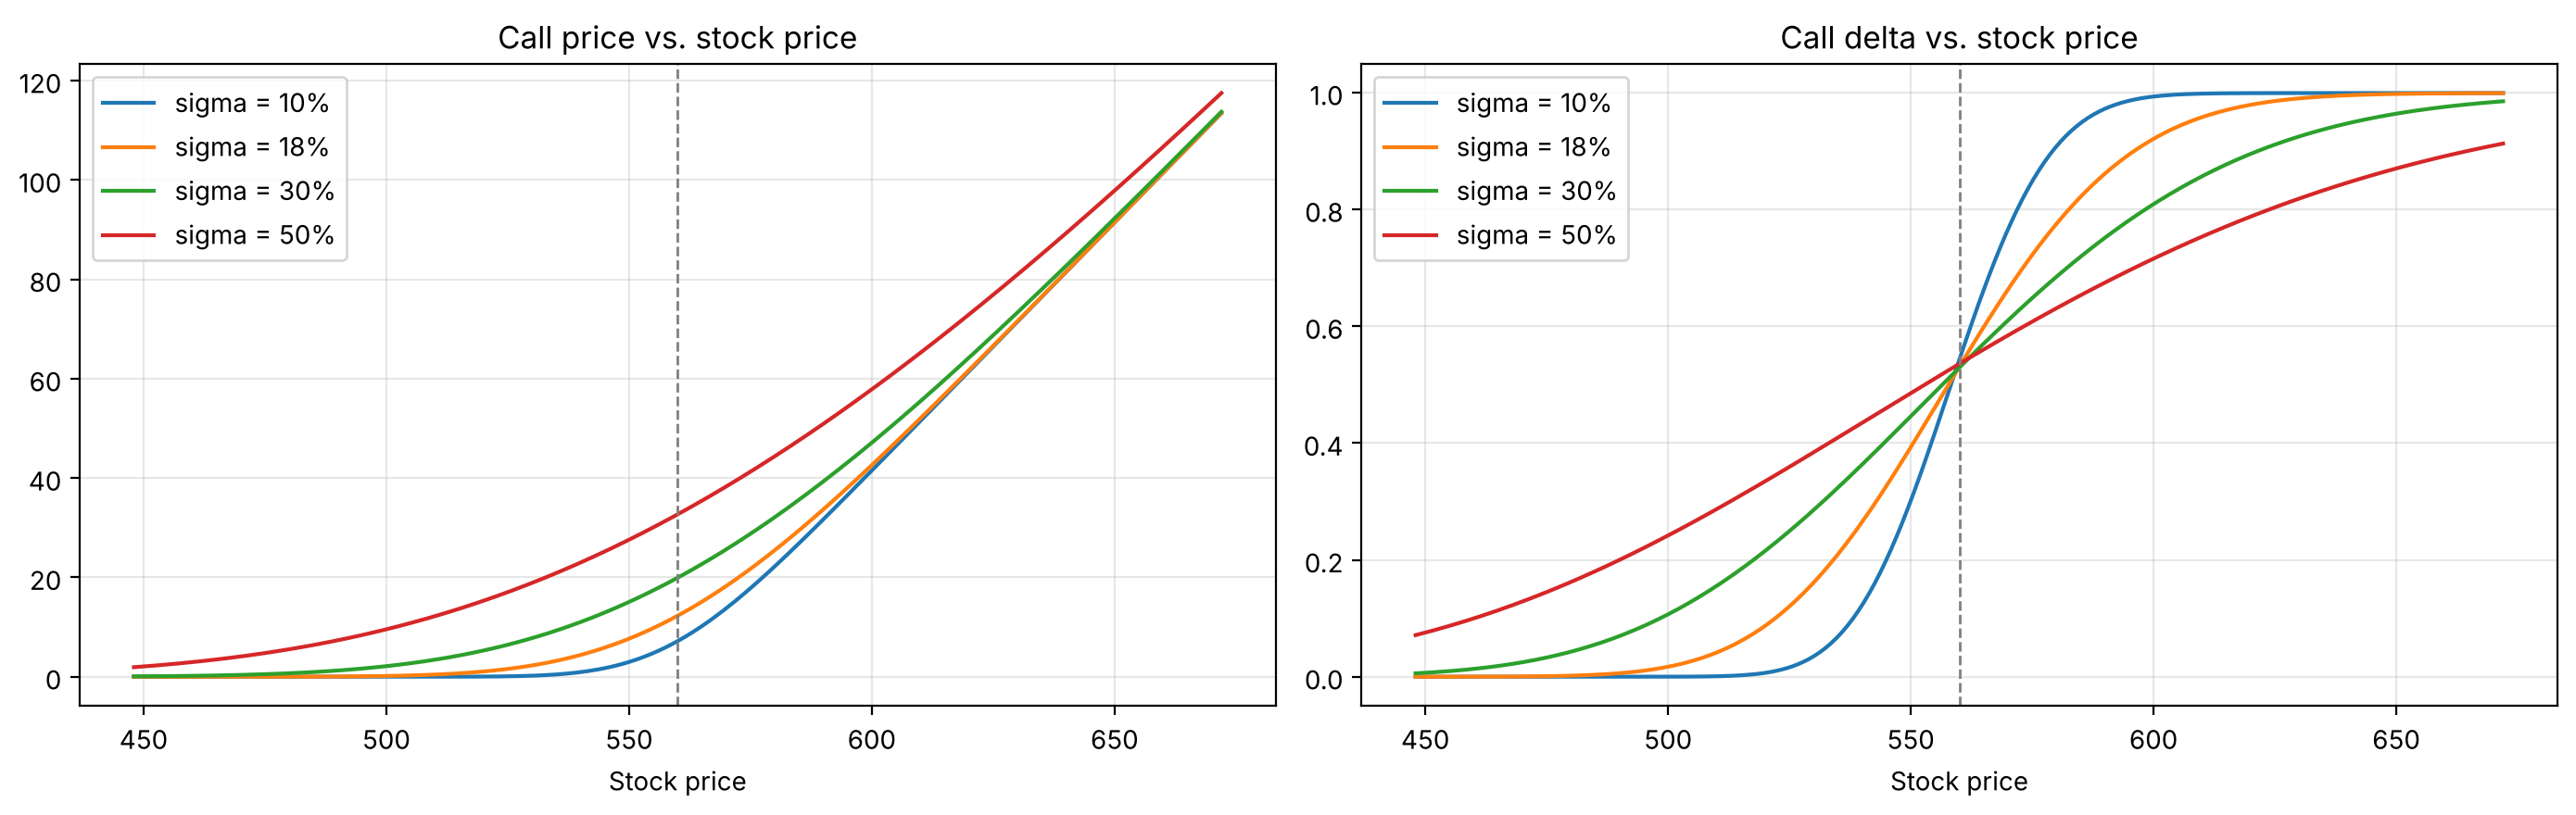

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for vol in [0.10, 0.18, 0.30, 0.50]:
    ax1.plot(stock_prices, [bsm_call(s, K, T, r, q, vol) for s in stock_prices], label=f'sigma = {vol:.0%}')
    ax2.plot(stock_prices, [delta(s, K, T, r, q, vol) for s in stock_prices], label=f'sigma = {vol:.0%}')
ax1.set_title('Call price vs. stock price'); ax2.set_title('Call delta vs. stock price')
for ax in (ax1, ax2):
    ax.axvline(K, color='gray', linestyle='--', linewidth=1)
    ax.set_xlabel('Stock price'); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

---
# 6. Optional: live market inputs

The function below pulls a live option chain from Yahoo Finance with `yfinance` and returns inputs for the closest-to-the-money call. Two details matter:

- **Strike choice:** it picks the strike nearest the spot price. Taking the first row of the chain instead returns a deep in-the-money strike with an unreliable implied volatility.
- **Dividend yield units:** Yahoo has reported dividend yield both as a decimal and as a percentage, so values above 0.2 are divided by 100.

It is not run by default, since live data changes every time.

In [9]:
def get_live_inputs(ticker='SPY', expiry_date=None, r=0.045):
    import datetime
    import yfinance as yf

    stock = yf.Ticker(ticker)
    S = stock.history(period='1d')['Close'].iloc[-1]
    expiry_date = expiry_date or stock.options[1]
    calls = stock.option_chain(expiry_date).calls
    row = calls.iloc[(calls['strike'] - S).abs().argmin()]

    T = (datetime.datetime.strptime(expiry_date, '%Y-%m-%d') - datetime.datetime.now()).days / 365
    q = stock.info.get('dividendYield') or 0.0
    if q > 0.2:
        q /= 100
    return S, row['strike'], T, r, q, row['impliedVolatility']

# Example:
# S, K, T, r, q, sigma = get_live_inputs('SPY')

---
# Summary

- Implemented BSM pricing and all five Greeks for dividend-paying stocks
- Verified the implementation with put-call parity and finite-difference checks
- Showed how each Greek depends on moneyness, time to expiry, and volatility, including the sharp rise in gamma and time decay near expiry

**Next steps:** simulate discrete delta hedging on simulated price paths to measure hedging error as a function of rebalancing frequency, and compare BSM prices with market prices across strikes to examine the volatility smile.